# Notebook 9 – Categorical Data Analysis

# Question 1 — What are Unique Categories?



## Step 1: Understand the concept

Unique Categories are the different values present in a categorical feature.

For example, the Contract feature contains categories such as:

- Month-to-month
- One year
- Two year

Identifying unique categories helps us understand what values are present in a categorical variable.

## Step 2: Demonstrate the concept

We will identify the unique categories in important categorical features such as:

- Gender
- Contract
- InternetService
- PaymentMethod
- Churn

This helps us understand the structure of the categorical data.


## Step 3: Implementation the concept

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "Contract",
    "PaymentMethod",
    "InternetService",
    "Churn"
]

for column in categorical_features:

    print(f"\n--- {column} ---")
    print(df[column].unique())


--- gender ---
['Female' 'Male']

--- SeniorCitizen ---
[0 1]

--- Partner ---
['Yes' 'No']

--- Dependents ---
['No' 'Yes']

--- Contract ---
['Month-to-month' 'One year' 'Two year']

--- PaymentMethod ---
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

--- InternetService ---
['DSL' 'Fiber optic' 'No']

--- Churn ---
['No' 'Yes']


## Code Explanation

- `.unique()` returns all unique categories in a column.
- Each categorical feature may contain a different number of categories.

### Expected Insight

This helps us understand what categories are available before performing further categorical analysis.

# Question 2 — What are Category Frequencies?


## Step 1: Understand the concept

Category Frequency means the number of observations belonging to each category.

For example, in the Churn column:

- Yes → Number of customers who churned
- No → Number of customers who did not churn

Frequency helps us understand how common each category is.

## Step 2: Demonstrate the concept

We will calculate category frequencies for important categorical variables.

This helps identify which categories have the highest and lowest number of observations.


## Step 3: Implementation the concept

In [2]:


for column in categorical_features:

    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- Contract ---
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

--- PaymentMethod ---
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- Churn ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## Code Explanation

`.value_counts()` counts how many times each category appears.

### Expected Insight

The output shows the frequency of every category in each categorical feature.

# Question 3 — Analyze Category Distribution


## Step 1: Understand the concept

Category Distribution shows the proportion of observations belonging to each category.

Frequency tells us the count.

Percentage distribution tells us how much of the dataset each category represents.

Percentage is useful when comparing categories with different total counts.

## Step 2: Demonstrate the concept

We will calculate the percentage distribution of important categorical variables.

For example, Churn can be analyzed to understand what percentage of customers stayed and what percentage left.


## Step 3: Implementation the concept

In [3]:


for column in categorical_features:

    percentage = (
        df[column]
        .value_counts(normalize=True)
        * 100
    )

    print(f"\n--- {column} ---")
    print(percentage.round(2))


--- gender ---
gender
Male      50.48
Female    49.52
Name: proportion, dtype: float64

--- SeniorCitizen ---
SeniorCitizen
0    83.79
1    16.21
Name: proportion, dtype: float64

--- Partner ---
Partner
No     51.7
Yes    48.3
Name: proportion, dtype: float64

--- Dependents ---
Dependents
No     70.04
Yes    29.96
Name: proportion, dtype: float64

--- Contract ---
Contract
Month-to-month    55.02
Two year          24.07
One year          20.91
Name: proportion, dtype: float64

--- PaymentMethod ---
PaymentMethod
Electronic check             33.58
Mailed check                 22.89
Bank transfer (automatic)    21.92
Credit card (automatic)      21.61
Name: proportion, dtype: float64

--- InternetService ---
InternetService
Fiber optic    43.96
DSL            34.37
No             21.67
Name: proportion, dtype: float64

--- Churn ---
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## Code Explanation

- `value_counts()` calculates category frequency.
- `normalize=True` converts frequencies into proportions.
- Multiplying by 100 converts proportions into percentages.

### Expected Insight

This shows how the observations are distributed across different categories.

# Question 4 — Visualize Category Distribution


## Step 1: Understand the concept

Bar charts and count plots are useful for visualizing categorical data.

They make it easier to compare category frequencies.

A taller bar represents a category with more observations.

## Step 2: Demonstrate the concept

We will create Count Plots for important categorical features.

This allows us to visually compare the number of observations in each category.


## Step 3: Implementation the concept

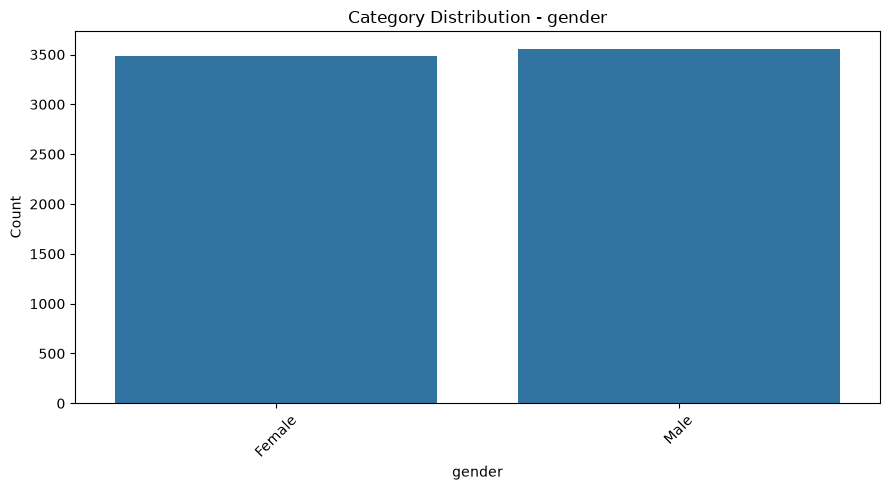

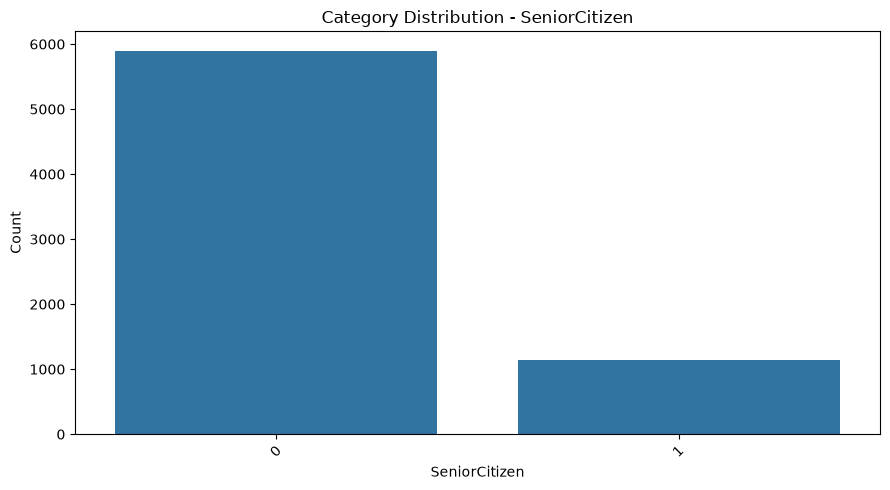

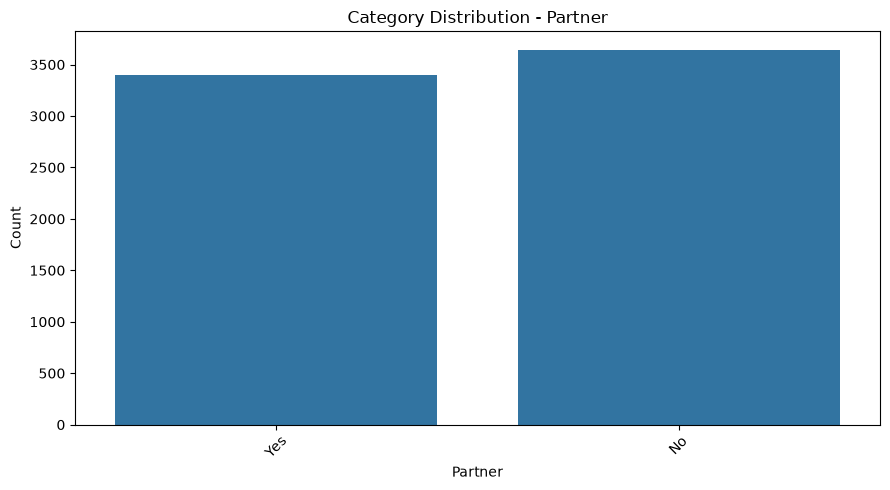

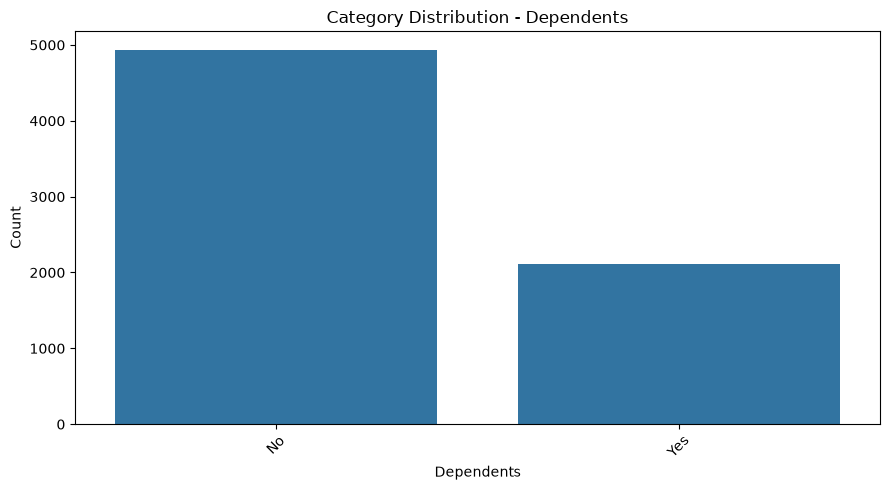

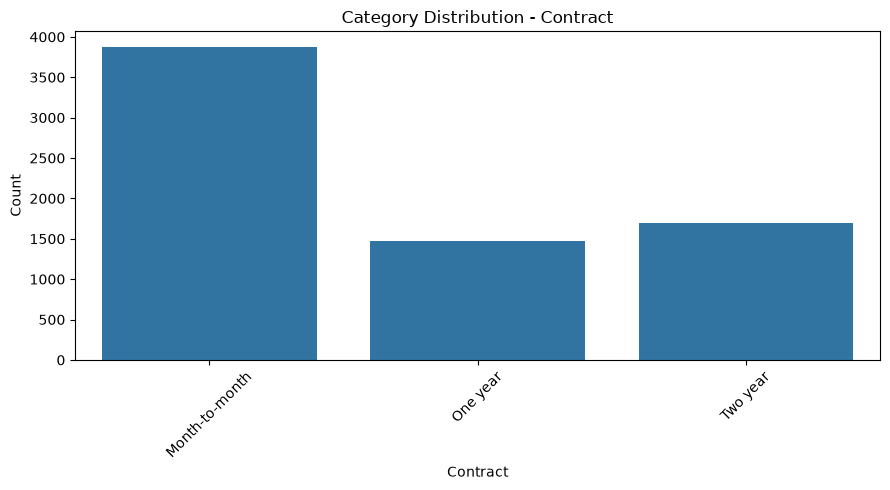

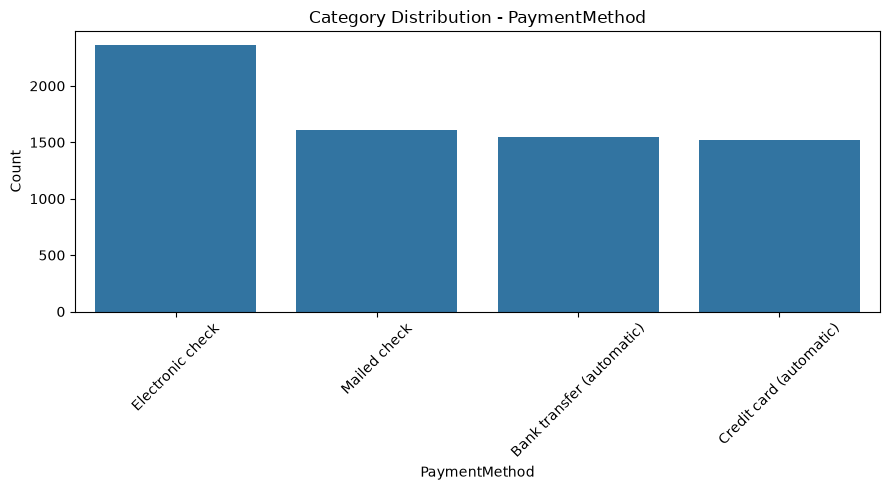

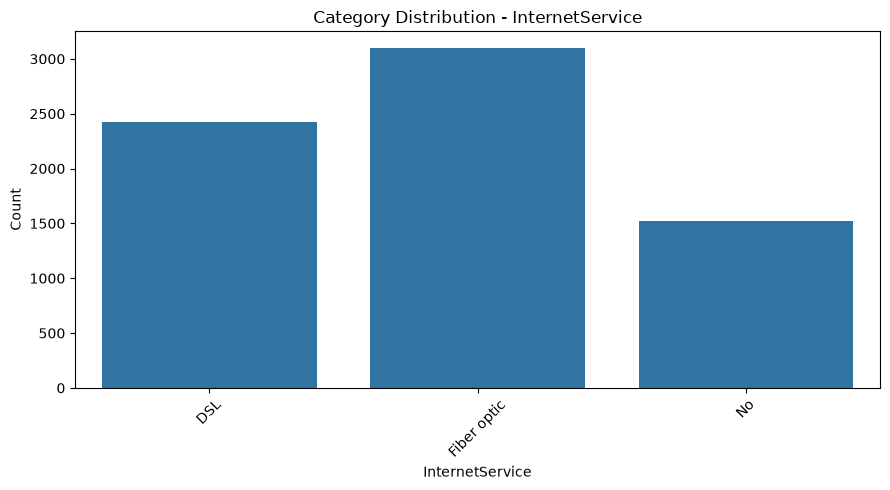

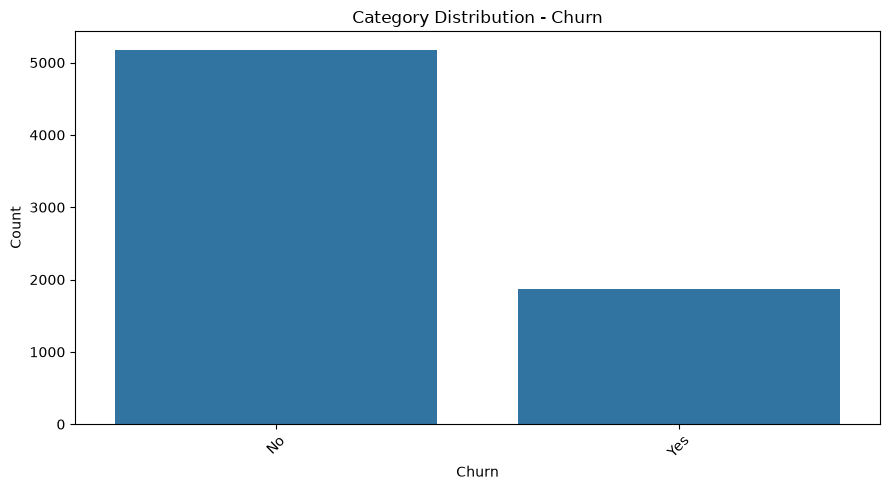

In [4]:


for column in categorical_features:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column
    )

    plt.title(f"Category Distribution - {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

## Code Explanation

- `sns.countplot()` displays the frequency of each category.
- `rotation=45` improves readability when category names are long.

### Expected Insight

The chart makes it easier to identify dominant and less common categories.

# Question 5 — Identify Rare Categories



## Step 1: Understand the concept

A Rare Category is a category that occurs very few times compared with other categories.

Rare categories may cause problems when building machine learning models, especially when there are very few observations for a category.

However, rare does not automatically mean that the category should be removed.

## Step 2: Demonstrate the concept

We will use a practical threshold of less than 1% of the dataset to identify potentially rare categories.

This is only a screening rule.

Business context should be considered before combining or removing a rare category.


## Step 3: Implementation the concept

In [5]:


for column in categorical_features:

    percentage = (
        df[column]
        .value_counts(normalize=True)
        * 100
    )

    rare_categories = percentage[
        percentage < 1
    ]

    print(f"\n--- {column} ---")

    if len(rare_categories) > 0:
        print("Potential Rare Categories:")
        print(rare_categories.round(2))
    else:
        print("No category is below the 1% threshold.")


--- gender ---
No category is below the 1% threshold.

--- SeniorCitizen ---
No category is below the 1% threshold.

--- Partner ---
No category is below the 1% threshold.

--- Dependents ---
No category is below the 1% threshold.

--- Contract ---
No category is below the 1% threshold.

--- PaymentMethod ---
No category is below the 1% threshold.

--- InternetService ---
No category is below the 1% threshold.

--- Churn ---
No category is below the 1% threshold.


## Code Explanation

The code calculates the percentage of each category.

Categories representing less than 1% are flagged as potentially rare.

### Important

Rare categories should not automatically be removed.

They may contain useful information.

# Question 6 — What is High Cardinality?


## Step 1: Understand the concept

Cardinality means the number of unique categories in a categorical feature.

High Cardinality means a categorical feature contains many unique categories.

For example, CustomerID has many unique values and therefore has high cardinality.

High-cardinality features can increase the number of features when encoding categorical data.

## Step 2: Demonstrate the concept

We will calculate the number of unique values in each categorical feature.

We can use this information to identify features with relatively high cardinality.


## Step 3: Implementation the concept

In [6]:


cardinality = df[categorical_features].nunique()

print("Cardinality of Categorical Features:")
print(cardinality.sort_values(ascending=False))

Cardinality of Categorical Features:
PaymentMethod      4
Contract           3
InternetService    3
gender             2
Dependents         2
Partner            2
SeniorCitizen      2
Churn              2
dtype: int64


## Code Explanation

`.nunique()` returns the number of unique categories in each feature.

A higher number indicates higher cardinality.

### Expected Insight

Features with many unique categories require careful handling during encoding.

# Question 7 — What is Low Cardinality?


## Step 1: Understand the concept

Low Cardinality means a categorical feature contains only a small number of unique categories.

Examples include:

- Gender
- Churn
- Partner
- Dependents

Low-cardinality features are usually easier to analyze and encode.

## Step 2: Demonstrate the concept

We will identify categorical features with a small number of unique categories.

For this dataset, we can use 5 or fewer unique categories as a practical screening threshold.


## Step 3: Implementation the concept

In [7]:


cardinality = df[categorical_features].nunique()

low_cardinality = cardinality[
    cardinality <= 5
]

print("Low Cardinality Features:")
print(low_cardinality)

Low Cardinality Features:
gender             2
SeniorCitizen      2
Partner            2
Dependents         2
Contract           3
PaymentMethod      4
InternetService    3
Churn              2
dtype: int64


## Code Explanation

The code selects categorical features containing 5 or fewer unique categories.

### Expected Insight

Low-cardinality features are generally easier to visualize and encode.

# Question 8 — Identify Category Imbalance


## Step 1: Understand the concept

Category Imbalance occurs when some categories contain significantly more observations than others.

For example, if one category contains 90% of observations and another contains only 10%, the feature is highly imbalanced.

Category imbalance can affect machine learning models and analysis.

## Step 2: Demonstrate the concept

We will analyze the percentage distribution of each categorical variable.

For this dataset, we can flag a feature when its largest category contains more than 80% of the observations as a practical screening rule.

This is not a strict statistical rule.


## Step 3: Implementation the concept

In [8]:


for column in categorical_features:

    distribution = (
        df[column]
        .value_counts(normalize=True)
        * 100
    )

    largest_category = distribution.max()

    print(
        f"{column}: "
        f"Largest Category = {largest_category:.2f}%"
    )

    if largest_category > 80:
        print("Potential Category Imbalance")
    else:
        print("No Severe Category Imbalance")

gender: Largest Category = 50.48%
No Severe Category Imbalance
SeniorCitizen: Largest Category = 83.79%
Potential Category Imbalance
Partner: Largest Category = 51.70%
No Severe Category Imbalance
Dependents: Largest Category = 70.04%
No Severe Category Imbalance
Contract: Largest Category = 55.02%
No Severe Category Imbalance
PaymentMethod: Largest Category = 33.58%
No Severe Category Imbalance
InternetService: Largest Category = 43.96%
No Severe Category Imbalance
Churn: Largest Category = 73.46%
No Severe Category Imbalance


## Code Explanation

The code finds the percentage of the largest category.

If one category contains more than 80% of observations, it is flagged as potentially imbalanced.

### Important

Imbalance does not always mean the data is incorrect.

# Question 9 — Analyze Categorical Variables Against Target Variable


## Step 1: Understand the concept

The target variable in this dataset is:

`Churn`

It tells us whether a customer left the company.

We can compare categorical variables with Churn to understand whether different customer groups have different churn patterns.

Important categorical variables include:

- Contract
- InternetService
- PaymentMethod
- Partner
- Dependents
- SeniorCitizen

## Step 2: Demonstrate the concept

We will calculate the Churn percentage within each category.

For example:

Contract → Churn

This allows us to compare the percentage of customers who churned within each contract type.

### AI/ML Use

These relationships can help identify categorical features that may be useful for predicting customer churn.


## Step 3: Implementation the concept

In [9]:


target_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "Partner",
    "Dependents",
    "SeniorCitizen"
]

for column in target_features:

    churn_percentage = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"\n--- {column} vs Churn ---")
    print(churn_percentage.round(2))


--- Contract vs Churn ---
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

--- InternetService vs Churn ---
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

--- PaymentMethod vs Churn ---
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11

--- Partner vs Churn ---
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

--- Dependents vs Churn ---
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

--- SeniorCitizen vs Churn ---
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1            

## Code Explanation

- `pd.crosstab()` creates a frequency table between two categorical variables.
- `normalize="index"` converts the counts into percentages within each category.
- Multiplying by 100 converts the values into percentages.

### Expected Insight

We can compare the percentage of customers who churned across different categories.

For example, different Contract types may show different churn percentages.

# Question 10 — Visualize Categorical Variables vs Churn


## Step 1: Understand the concept

A Count Plot can show the relationship between a categorical feature and Churn.

Each category is divided into:

- Churn = Yes
- Churn = No

This makes it easier to compare customer behavior across categories.

## Step 2: Demonstrate the concept

We will visualize:

- Contract vs Churn
- InternetService vs Churn
- PaymentMethod vs Churn

These relationships can reveal which customer groups have higher churn counts.


## Step 3: Implementation the concept

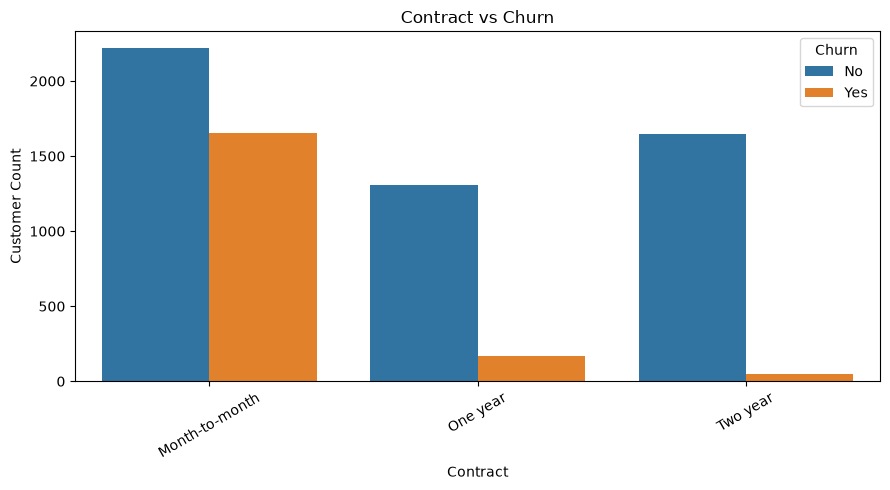

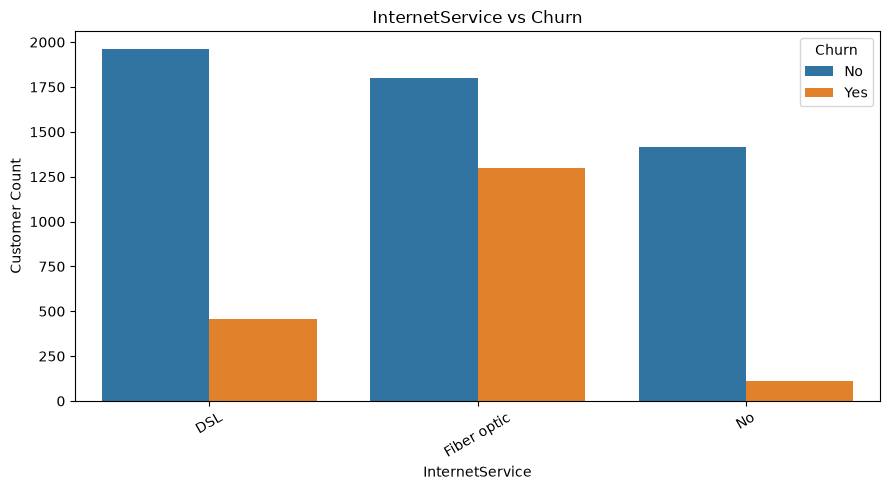

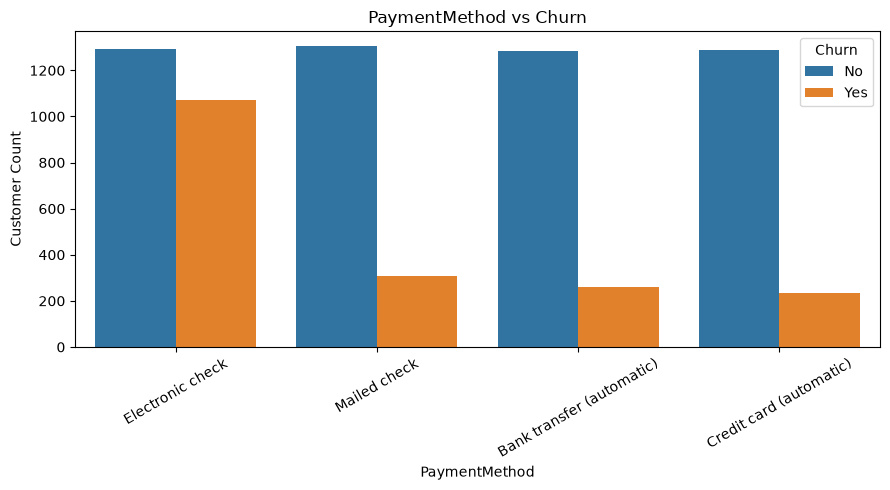

In [10]:


for column in target_features[:3]:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        hue="Churn"
    )

    plt.title(f"{column} vs Churn")
    plt.xlabel(column)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

## Code Explanation

- `x=column` displays the categorical feature.
- `hue="Churn"` separates customers based on the target variable.
- The resulting bars allow us to compare Churn = Yes and Churn = No.

### Expected Insight

The chart helps identify categories where churn appears relatively higher or lower.

# Question 11 — Identify Important Categorical Relationships with Churn


## Step 1: Understand the concept

An important categorical relationship exists when the Churn percentage differs noticeably between categories.

For example:

- Contract type may have different churn rates.
- Internet service type may have different churn patterns.
- Payment method may show different churn percentages.

This does not prove that the categorical feature causes churn.

It only shows an observed relationship in the dataset.

## Step 2: Demonstrate the concept

We will calculate the churn rate for each category.

The category with the highest Churn = Yes percentage can be identified as having a higher observed churn rate.

The category with the lowest percentage can be identified as having a lower observed churn rate.


## Step 3: Implementation the concept

In [11]:


for column in target_features:

    churn_rate = (
        df.groupby(column)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\n--- Churn Rate by {column} ---")
    print(churn_rate.round(2))


--- Churn Rate by Contract ---
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

--- Churn Rate by InternetService ---
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

--- Churn Rate by PaymentMethod ---
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

--- Churn Rate by Partner ---
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

--- Churn Rate by Dependents ---
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64

--- Churn Rate by SeniorCitizen ---
SeniorCitizen
1    41.68
0    23.61
Name: Churn, dtype: float64


## Code Explanation

The code calculates the percentage of customers who churned within each category.

- `groupby()` creates groups based on the categorical feature.
- `(x == "Yes")` identifies churned customers.
- `.mean() * 100` calculates the churn percentage.

### Expected Insight

This allows us to rank categories from higher observed churn rate to lower observed churn rate.

These relationships can be useful during feature analysis for churn prediction.

# Notebook 9 – Categorical Data Analysis Summary

### Topics Covered

- Unique Categories
- Category Frequencies
- Category Distribution
- Rare Categories
- High Cardinality
- Low Cardinality
- Category Imbalance

### Target Variable Analysis

The target variable used was:

`Churn`

Important categorical variables were compared with Churn to identify differences in customer churn rates.

### Key Analysis

We identified:

- The unique categories present in each feature.
- The frequency of each category.
- The percentage distribution of categories.
- Potential rare categories.
- High and low cardinality features.
- Potential category imbalance.
- Relationships between categorical variables and Churn.

### Important Note

Rare categories should not automatically be removed.

High cardinality should not automatically mean that a feature must be dropped.

Category imbalance does not mean that the data is incorrect.

Categorical variables should be evaluated using both statistical analysis and business context.

### Conclusion

Categorical Data Analysis helps us understand customer groups and identify categorical features that may be useful for machine learning and customer churn prediction.